In [1]:
from __future__ import print_function
import os
import cv2 
import numpy as np
import pandas as pd   
import matplotlib.pyplot as plt
from PIL import Image
from pillow_heif import register_heif_opener
import random
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.model_selection import KFold, cross_val_score, cross_validate
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold
from skimage.feature import local_binary_pattern
import warnings
warnings.filterwarnings("ignore")

In [3]:
GROUP = "C8"
DTYPE="LBP"
DIR_TRAIN = "DATA/TRAINING/"
GROUP_path = DIR_TRAIN+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path = os.listdir(GROUP_path)
resume = []
data_path = []
for HH in HH_path:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT = pd.DataFrame(resume)    # values
pdDT.columns = ["Humidity", "numberImages", "pathImages"]
pdDT

,Humidity,numberImages,pathImages
0,C8_10,30,"[DATA/TRAINING/C8/C8_10/IMG_8678.HEIC, DATA/TR..."
1,C8_11,25,"[DATA/TRAINING/C8/C8_11/IMG_8730.HEIC, DATA/TR..."
2,C8_12,25,"[DATA/TRAINING/C8/C8_12/IMG_8761.HEIC, DATA/TR..."
3,C8_13,25,"[DATA/TRAINING/C8/C8_13/IMG_8793.HEIC, DATA/TR..."
4,C8_14,25,"[DATA/TRAINING/C8/C8_14/IMG_8823.HEIC, DATA/TR..."
5,C8_15,26,"[DATA/TRAINING/C8/C8_15/IMG_8855.HEIC, DATA/TR..."
6,C8_16,25,"[DATA/TRAINING/C8/C8_16/IMG_8886.HEIC, DATA/TR..."


In [4]:
def read_imgHEIC(pic_path):
    register_heif_opener(); im = Image.open(pic_path)
    return cv2.cvtColor(np.array(im), cv2.COLOR_RGB2BGR)

In [5]:
def flip_image_vertical(image):
    height, width, channels = image.shape
    if(height < width):
        image = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)
    return image

In [6]:
def resize_image(img, scale_percent = 10):
     # percent of original size
    width = int(img.shape[1] * scale_percent / 100)
    height = int(img.shape[0] * scale_percent / 100)
    dim = (width, height)
    #print(dim)
    # resize image
    resized = cv2.resize(img, dim, interpolation = cv2.INTER_AREA)
    return resized

Text(0.5, 1.0, '16% IMG_8678.HEIC')

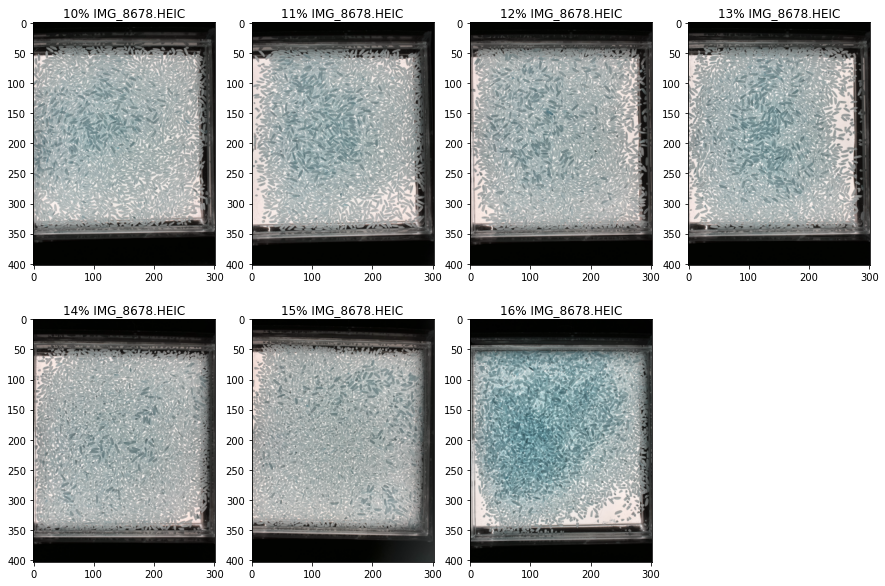

In [7]:
fig=plt.figure(figsize=(15, 10)) 
ax1 = fig.add_subplot(2,4,1); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[0][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax1.imshow(image); ax1.set_title("10% " + data_path[0][0].split("/")[4])
ax2 = fig.add_subplot(2,4,2); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[1][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax2.imshow(image); ax2.set_title("11% "+ data_path[0][0].split("/")[4])
ax3 = fig.add_subplot(2,4,3); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[2][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax3.imshow(image); ax3.set_title("12% "+ data_path[0][0].split("/")[4])
ax4 = fig.add_subplot(2,4,4); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[3][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax4.imshow(image); ax4.set_title("13% "+ data_path[0][0].split("/")[4])
ax5 = fig.add_subplot(2,4,5); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[4][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax5.imshow(image); ax5.set_title("14% "+ data_path[0][0].split("/")[4])
ax6 = fig.add_subplot(2,4,6); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[5][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax6.imshow(image); ax6.set_title("15% "+ data_path[0][0].split("/")[4])
ax7 = fig.add_subplot(2,4,7); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[6][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax7.imshow(image); ax7.set_title("16% "+ data_path[0][0].split("/")[4])

In [8]:
def fd_gray(gray, bins, mask=None):
    # compute the gray color histogram
    hist  = cv2.calcHist([gray], [0], None, [bins], [0, 256])
    # normalize the histogram
    cv2.normalize(hist, hist)
    # return the histogram
    return hist, hist.flatten()

In [154]:
#Parameters
HH = ['10', '11', '12', '13', '14', '15', '16']
#bins=44; #width=2024; height=3032; 
scale=3
dtHH=[]
for lstImgs, H in zip(data_path, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        #print(image.shape)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

        # Uniform LBP is used
        P=16; R=2
        lbp_ = local_binary_pattern(gray, P, R, method='uniform')
        n_bins = int(lbp_.max() + 1)
        hist_, bin_edges = np.histogram(lbp_.ravel(), bins=n_bins, range=(0, n_bins), density=True)
        arr_img_hist.append(hist_)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["P"] = P
    pdGrayFeatures["R"] = R
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH.append(pdGrayFeatures)

In [155]:
result = pd.concat(dtHH)

DIR= "FEATURES/ORIGINAL/GLOBAL/TRAINING/"; 
result.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'_'+str(P)+'_'+str(R)+'bins.csv', index=False)
result.head(10)

,0,1,2,3,4,5,6,7,8,9,...,16,17,scale,P,R,height,width,channels,IMAGENAME,HUMIDITY
0,0.073889,0.052778,0.023611,0.012963,0.010463,0.013889,0.013519,0.029815,0.049444,0.056574,...,0.155093,0.371574,3,16,2,120,90,3,IMG_8678.HEIC,10
1,0.070833,0.050185,0.024444,0.014259,0.012222,0.013611,0.016944,0.035926,0.047685,0.062222,...,0.147685,0.358889,3,16,2,120,90,3,IMG_8679.HEIC,10
2,0.075278,0.053704,0.022870,0.014444,0.010926,0.015833,0.015648,0.033611,0.039074,0.053056,...,0.136944,0.377315,3,16,2,120,90,3,IMG_8680.HEIC,10
3,0.075370,0.048611,0.023519,0.015648,0.010741,0.015741,0.017778,0.033796,0.044630,0.056481,...,0.149907,0.364722,3,16,2,120,90,3,IMG_8682.HEIC,10
4,0.072222,0.053611,0.023704,0.013889,0.008704,0.014074,0.017778,0.031852,0.044537,0.059259,...,0.142593,0.373611,3,16,2,120,90,3,IMG_8686.HEIC,10
5,0.071019,0.053426,0.020741,0.008889,0.008056,0.013148,0.013148,0.029907,0.045278,0.053426,...,0.155833,0.381481,3,16,2,120,90,3,IMG_8693.HEIC,10
6,0.080000,0.051944,0.024074,0.013519,0.010278,0.012963,0.012222,0.026111,0.040648,0.047870,...,0.158333,0.382037,3,16,2,120,90,3,IMG_8701.HEIC,10
7,0.079167,0.059167,0.023889,0.011019,0.009722,0.011019,0.010833,0.024352,0.037130,0.047037,...,0.161296,0.384167,3,16,2,120,90,3,IMG_8702.HEIC,10
8,0.081389,0.056759,0.023704,0.012870,0.008611,0.010093,0.010463,0.025926,0.039537,0.046204,...,0.166574,0.381667,3,16,2,120,90,3,IMG_8703.HEIC,10
9,0.076296,0.056667,0.024259,0.011481,0.008519,0.011944,0.012778,0.026944,0.039630,0.048519,...,0.161019,0.383611,3,16,2,120,90,3,IMG_8704.HEIC,10


# Classification

In [156]:
dtFeatures=result#.drop(['IMAGENAME'], axis=1)
#dtFeatures.head()
X = dtFeatures.values[:, :-8]
#X

In [157]:

# Normalization -> values[0-1]
scaler = MinMaxScaler()
X_scale = scaler.fit_transform(X)     
y = dtFeatures.values[:, -1]
#y

In [158]:
def compute_classification_metrics(y_pred, y_test):
    acc = np.sum(y_pred == y_test) / float(len(y_test))
    precision =np.mean(precision_score(y_test, y_pred, average=None, zero_division=1))
    recall =np.mean(recall_score(y_test, y_pred, average=None, zero_division=1))
    F1 = 2 * (precision * recall) / (precision + recall)
    return acc, precision, recall, F1

In [159]:
def get_CV_CLASSIFICATION_MODELS(model, X, y, rescale=False):
    dt_lg_test=[]  
    if rescale==True:
        y=y-10
        #print(y)
    kfold = StratifiedKFold(n_splits=10, shuffle=True)
    k_fold=1
    for train_index , test_index in kfold.split(X, y):

        X_train , X_test = X[train_index], X[test_index]
        y_train , y_test = y[train_index], y[test_index]
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)  # predict label

        [acc, precision, recall, F1] = compute_classification_metrics(y_pred, y_test)
        dt_lg_test.append([k_fold, acc, precision, recall, F1])
        k_fold=k_fold+1
    return dt_lg_test

#### Random Forest Classifier

In [160]:
modelRFC=RandomForestClassifier(n_estimators=1000) 
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelRFC, X_scale, y)
modelName="RF_C"

In [161]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["P"]=P; dtFoldTrain["R"]=R; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'_'+str(P)+'_'+str(R)+'_bins.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,P,R,height,width,channels
0,1,0.736842,0.690476,0.714286,0.702179,LBP,C8,RF_C,3,16,2,120,90,3
1,2,0.666667,0.633333,0.619048,0.626109,LBP,C8,RF_C,3,16,2,120,90,3
2,3,0.666667,0.771429,0.666667,0.715232,LBP,C8,RF_C,3,16,2,120,90,3
3,4,0.611111,0.583333,0.571429,0.577320,LBP,C8,RF_C,3,16,2,120,90,3
4,5,0.722222,0.835714,0.738095,0.783877,LBP,C8,RF_C,3,16,2,120,90,3
5,6,0.833333,0.880952,0.809524,0.843729,LBP,C8,RF_C,3,16,2,120,90,3
6,7,0.722222,0.773810,0.714286,0.742857,LBP,C8,RF_C,3,16,2,120,90,3
7,8,0.833333,0.857143,0.857143,0.857143,LBP,C8,RF_C,3,16,2,120,90,3
8,9,0.888889,0.928571,0.857143,0.891429,LBP,C8,RF_C,3,16,2,120,90,3
9,10,0.777778,0.847619,0.761905,0.802480,LBP,C8,RF_C,3,16,2,120,90,3


In [162]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()
#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultRF=result
resultRF

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,LBP,C8,RF_C,0.745906,0.730952,0.754235,0.780238


### MLP Classifier

In [163]:
# Import MLPClassifer 
from sklearn.neural_network import MLPClassifier

In [164]:
modelMLPC = MLPClassifier(max_iter=500)
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelMLPC, X_scale, y)
modelName='MLP_C'

In [165]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["P"]=P; dtFoldTrain["R"]=R; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'_'+str(P)+'_'+str(R)+'_bins.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,P,R,height,width,channels
0,1,0.736842,0.776190,0.714286,0.743953,LBP,C8,MLP_C,3,16,2,120,90,3
1,2,0.722222,0.823810,0.738095,0.778600,LBP,C8,MLP_C,3,16,2,120,90,3
2,3,0.611111,0.619048,0.619048,0.619048,LBP,C8,MLP_C,3,16,2,120,90,3
3,4,0.777778,0.785714,0.785714,0.785714,LBP,C8,MLP_C,3,16,2,120,90,3
4,5,0.833333,0.845238,0.833333,0.839243,LBP,C8,MLP_C,3,16,2,120,90,3
5,6,0.944444,0.964286,0.928571,0.946092,LBP,C8,MLP_C,3,16,2,120,90,3
6,7,0.777778,0.821429,0.785714,0.803175,LBP,C8,MLP_C,3,16,2,120,90,3
7,8,0.722222,0.821429,0.714286,0.764120,LBP,C8,MLP_C,3,16,2,120,90,3
8,9,0.722222,0.773810,0.714286,0.742857,LBP,C8,MLP_C,3,16,2,120,90,3
9,10,0.666667,0.714286,0.690476,0.702179,LBP,C8,MLP_C,3,16,2,120,90,3


In [166]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,LBP,C8,MLP_C,0.751462,0.752381,0.772498,0.794524


### XGBoost Classifier

In [167]:
modelXGBC = xgb.XGBClassifier()
y = np.array([int(x) for x in y])
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelXGBC, X_scale, y, True)
modelName='XGB_C'

In [168]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["P"]=P; dtFoldTrain["R"]=R; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'_'+str(P)+'_'+str(R)+'_bins.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,P,R,height,width,channels
0,1,0.684211,0.728571,0.690476,0.709012,LBP,C8,XGB_C,3,16,2,120,90,3
1,2,0.777778,0.785714,0.761905,0.773626,LBP,C8,XGB_C,3,16,2,120,90,3
2,3,0.611111,0.652381,0.666667,0.659446,LBP,C8,XGB_C,3,16,2,120,90,3
3,4,0.777778,0.809524,0.785714,0.797441,LBP,C8,XGB_C,3,16,2,120,90,3
4,5,0.777778,0.878571,0.761905,0.816090,LBP,C8,XGB_C,3,16,2,120,90,3
5,6,0.666667,0.738095,0.642857,0.687192,LBP,C8,XGB_C,3,16,2,120,90,3
6,7,0.777778,0.833333,0.761905,0.796020,LBP,C8,XGB_C,3,16,2,120,90,3
7,8,0.722222,0.809524,0.714286,0.758929,LBP,C8,XGB_C,3,16,2,120,90,3
8,9,0.833333,0.907143,0.833333,0.868673,LBP,C8,XGB_C,3,16,2,120,90,3
9,10,0.611111,0.761905,0.619048,0.683087,LBP,C8,XGB_C,3,16,2,120,90,3


In [169]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,LBP,C8,XGB_C,0.723977,0.72381,0.754952,0.790476


# External validation

In [170]:
DIR_TEST = "DATA/TEST/"
GROUP_path = DIR_TEST+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path_test = os.listdir(GROUP_path)
resume = []
data_path_test = []
for HH in HH_path_test:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path_test.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT_test = pd.DataFrame(resume)    # values
pdDT_test.columns = ["Humidity", "numberImages", "pathImages"]
pdDT_test

,Humidity,numberImages,pathImages
0,C8_10,5,"[DATA/TEST/C8/C8_10/IMG_8685.HEIC, DATA/TEST/C..."
1,C8_11,5,"[DATA/TEST/C8/C8_11/IMG_8732.HEIC, DATA/TEST/C..."
2,C8_12,5,"[DATA/TEST/C8/C8_12/IMG_8762.HEIC, DATA/TEST/C..."
3,C8_13,5,"[DATA/TEST/C8/C8_13/IMG_8792.HEIC, DATA/TEST/C..."
4,C8_14,5,"[DATA/TEST/C8/C8_14/IMG_8827.HEIC, DATA/TEST/C..."
5,C8_15,5,"[DATA/TEST/C8/C8_15/IMG_8854.HEIC, DATA/TEST/C..."
6,C8_16,5,"[DATA/TEST/C8/C8_16/IMG_8901.HEIC, DATA/TEST/C..."


In [171]:
HH=['10', '11', '12', '13', '14', '15', '16']

In [172]:
dtHH_test=[]
for lstImgs, H in zip(data_path_test, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        # Uniform LBP is used
        P=16; R=2
        lbp_ = local_binary_pattern(gray, P, R, method='uniform')
        n_bins = int(lbp_.max() + 1)
        hist_, bin_edges = np.histogram(lbp_.ravel(), bins=n_bins, range=(0, n_bins), density=True)
        arr_img_hist.append(hist_)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["P"] = P
    pdGrayFeatures["R"] = R
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH_test.append(pdGrayFeatures)

In [173]:
result_test = pd.concat(dtHH_test)

DIR= "FEATURES/ORIGINAL/GLOBAL/TESTING/"; 
result_test.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'_'+str(P)+'_'+str(R)+'bins.csv', index=False)
result_test.head(10)

,0,1,2,3,4,5,6,7,8,9,...,16,17,scale,P,R,height,width,channels,IMAGENAME,HUMIDITY
0,0.073704,0.049630,0.024815,0.014444,0.011944,0.013889,0.017222,0.026574,0.041111,0.052685,...,0.149815,0.381759,3,16,2,120,90,3,IMG_8685.HEIC,10
1,0.072593,0.054630,0.019167,0.011574,0.009537,0.014815,0.018056,0.035185,0.041944,0.056759,...,0.142130,0.379352,3,16,2,120,90,3,IMG_8687.HEIC,10
2,0.076574,0.049074,0.021944,0.010741,0.008796,0.014352,0.014259,0.031852,0.042130,0.055278,...,0.153241,0.378611,3,16,2,120,90,3,IMG_8688.HEIC,10
3,0.073519,0.057130,0.024074,0.011667,0.006852,0.011759,0.013241,0.029907,0.045926,0.049722,...,0.157870,0.378519,3,16,2,120,90,3,IMG_8696.HEIC,10
4,0.075370,0.052315,0.021296,0.012037,0.008056,0.009444,0.012315,0.028426,0.041481,0.053426,...,0.163704,0.386667,3,16,2,120,90,3,IMG_8699.HEIC,10
0,0.075370,0.054352,0.027130,0.011944,0.009352,0.012315,0.013611,0.025463,0.037593,0.056759,...,0.157778,0.375185,3,16,2,120,90,3,IMG_8732.HEIC,11
1,0.079815,0.052407,0.023426,0.011111,0.007778,0.011574,0.013148,0.026296,0.045185,0.059630,...,0.158426,0.374722,3,16,2,120,90,3,IMG_8735.HEIC,11
2,0.080648,0.054259,0.023889,0.012963,0.009167,0.010833,0.010741,0.024537,0.040833,0.057870,...,0.159907,0.370000,3,16,2,120,90,3,IMG_8737.HEIC,11
3,0.076111,0.052222,0.020185,0.010370,0.009167,0.011852,0.012870,0.030833,0.046667,0.062222,...,0.158611,0.378704,3,16,2,120,90,3,IMG_8739.HEIC,11
4,0.075000,0.055093,0.023889,0.011296,0.006667,0.009815,0.012685,0.028796,0.054444,0.068796,...,0.155833,0.361667,3,16,2,120,90,3,IMG_8740.HEIC,11


In [174]:
dtFeaturesTest=result_test#.drop(['IMAGENAME'], axis=1)
#dtFeaturesTest.head()

In [175]:
X_test = dtFeaturesTest.values[:, :-8]
#X_test

In [176]:
X_test_scale = scaler.transform(X_test)     
y_test = dtFeaturesTest.values[:, -1]
y_test

array(['10', '10', '10', '10', '10', '11', '11', '11', '11', '11', '12',
       '12', '12', '12', '12', '13', '13', '13', '13', '13', '14', '14',
       '14', '14', '14', '15', '15', '15', '15', '15', '16', '16', '16',
       '16', '16'], dtype=object)

## RFC

In [177]:
y_pred = modelRFC.predict(X_test_scale)  # predict label

In [178]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       1.00      0.40      0.57         5
     Class 1       0.60      0.60      0.60         5
     Class 2       0.50      1.00      0.67         5
     Class 3       0.50      0.40      0.44         5
     Class 4       0.80      0.80      0.80         5
     Class 5       1.00      0.80      0.89         5
     Class 6       0.80      0.80      0.80         5

    accuracy                           0.69        35
   macro avg       0.74      0.69      0.68        35
weighted avg       0.74      0.69      0.68        35



## MLP

In [179]:
y_pred = modelMLPC.predict(X_test_scale)  # predict label

In [180]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       1.00      0.40      0.57         5
     Class 1       0.80      0.80      0.80         5
     Class 2       0.62      1.00      0.77         5
     Class 3       0.67      0.80      0.73         5
     Class 4       0.80      0.80      0.80         5
     Class 5       1.00      0.80      0.89         5
     Class 6       0.80      0.80      0.80         5

    accuracy                           0.77        35
   macro avg       0.81      0.77      0.77        35
weighted avg       0.81      0.77      0.77        35



## XGBC

In [181]:
y_pred = modelXGBC.predict(X_test_scale) 

In [182]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
y_test = np.array([int(x) for x in y_test])
res = classification_report(y_test-10, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       1.00      0.40      0.57         5
     Class 1       0.75      0.60      0.67         5
     Class 2       0.71      1.00      0.83         5
     Class 3       0.44      0.80      0.57         5
     Class 4       0.80      0.80      0.80         5
     Class 5       1.00      1.00      1.00         5
     Class 6       1.00      0.60      0.75         5

    accuracy                           0.74        35
   macro avg       0.82      0.74      0.74        35
weighted avg       0.82      0.74      0.74        35

